# Customer Churn Analysis

**Goal:** find out which customers leave a telecom company, why they are likely to leave, and what the business can do about it.

**Dataset:** `churn.csv` (Telco customer churn): 7,043 customers, 21 columns covering demographics, services, contract, billing and whether the customer churned.

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Clean the data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as text because a few rows contain blank spaces. Convert it to numbers; blanks become `NaN`.

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing values after conversion:')
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values after conversion:
TotalCharges    11
dtype: int64


These customers have `tenure = 0` (brand new), so they have no charges yet. With only a handful of rows, dropping them is safe.

In [4]:
df = df.dropna().copy()
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})   # numeric so we can take averages
print('Rows remaining:', len(df))
print('Duplicate customers:', df['customerID'].duplicated().sum())

Rows remaining: 7032
Duplicate customers: 0


## 3. Overall churn rate

Overall churn rate: 26.6%


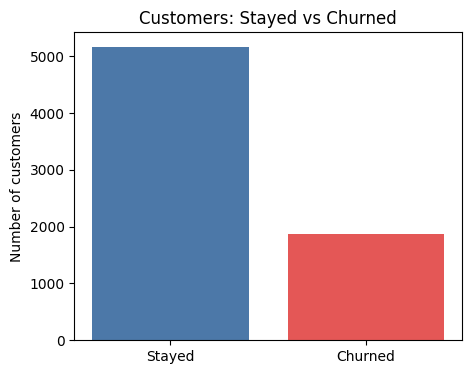

In [5]:
churn_rate = df['Churn'].mean() * 100
print(f'Overall churn rate: {churn_rate:.1f}%')

counts = df['Churn'].value_counts().sort_index()
plt.figure(figsize=(5, 4))
plt.bar(['Stayed', 'Churned'], counts.values, color=['#4C78A8', '#E45756'])
plt.title('Customers: Stayed vs Churned')
plt.ylabel('Number of customers')
plt.show()

About **1 in 4 customers churns**, so this is a meaningful problem and the classes are imbalanced (more stayers than leavers).

## 4. Churn by contract type

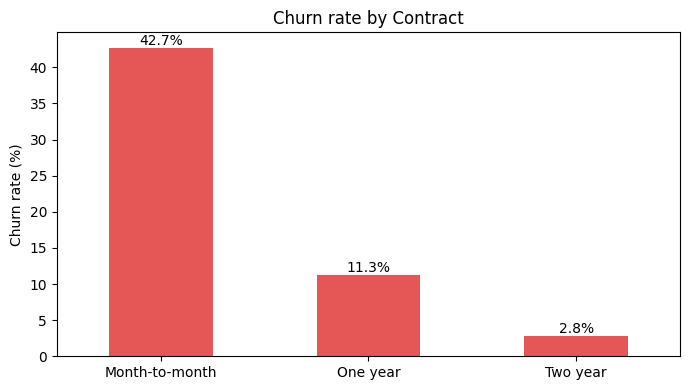

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

In [6]:
def churn_by(col, title=None, order=None):
    rate = df.groupby(col)['Churn'].mean() * 100
    if order:
        rate = rate.reindex(order)
    ax = rate.plot(kind='bar', color='#E45756', figsize=(7, 4), rot=0)
    ax.set_title(title or f'Churn rate by {col}')
    ax.set_ylabel('Churn rate (%)')
    ax.set_xlabel('')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
    return rate.round(1)

churn_by('Contract')

**Month-to-month customers churn far more** than customers on one- or two-year contracts. Contract length is the strongest single signal in this dataset.

## 5. Churn by tenure

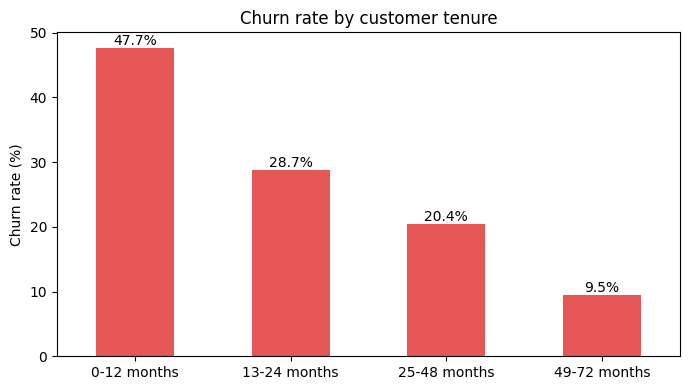

TenureGroup
0-12 months     47.7
13-24 months    28.7
25-48 months    20.4
49-72 months     9.5
Name: Churn, dtype: float64

In [7]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 72],
                           labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months'])
churn_by('TenureGroup', 'Churn rate by customer tenure')

Churn is highest in the **first year** and falls steadily the longer a customer stays. Early retention matters most.

## 6. Churn by internet service and add-ons

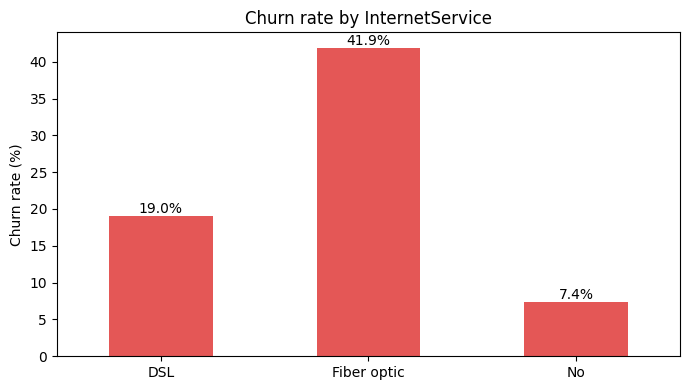

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64

In [8]:
churn_by('InternetService')

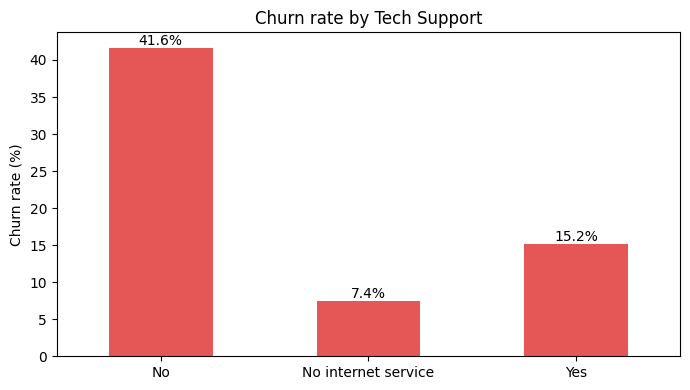

TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: Churn, dtype: float64

In [9]:
churn_by('TechSupport', 'Churn rate by Tech Support')

**Fiber optic customers churn about twice as much as DSL customers**, and customers **without tech support** churn much more than those with it. Possible causes: higher price, service quality issues, or a lack of support.

## 7. Churn by payment method

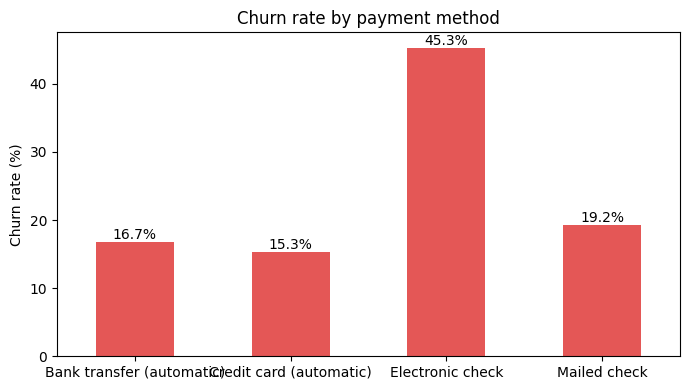

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.3
Electronic check             45.3
Mailed check                 19.2
Name: Churn, dtype: float64

In [10]:
churn_by('PaymentMethod', 'Churn rate by payment method')

**Electronic check** users churn at roughly three times the rate of customers on automatic bank transfer or credit card payments.

## 8. Monthly charges and tenure: churned vs retained

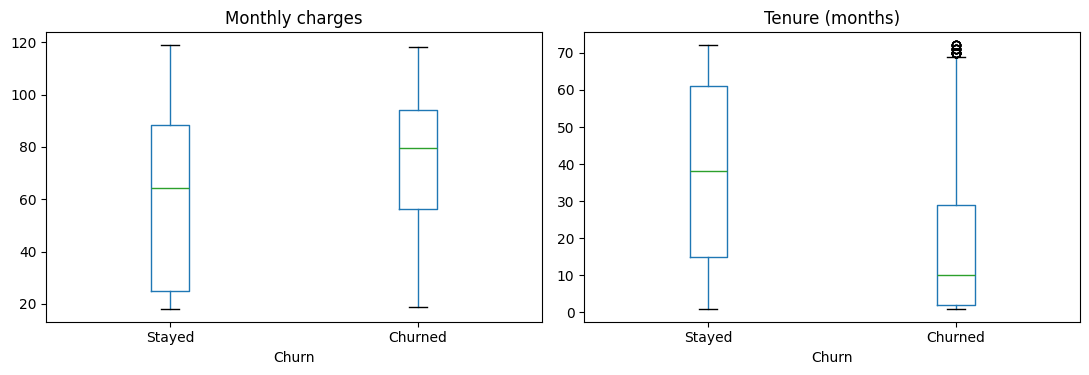

,MonthlyCharges,tenure
Churn,,
Stayed,64.45,38.0
Churned,79.65,10.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df.boxplot(column='MonthlyCharges', by='Churn', ax=axes[0], grid=False)
axes[0].set_title('Monthly charges')
axes[0].set_xticklabels(['Stayed', 'Churned'])

df.boxplot(column='tenure', by='Churn', ax=axes[1], grid=False)
axes[1].set_title('Tenure (months)')
axes[1].set_xticklabels(['Stayed', 'Churned'])

fig.suptitle('')
plt.tight_layout()
plt.show()

df.groupby('Churn')[['MonthlyCharges', 'tenure']].median().rename(index={0: 'Stayed', 1: 'Churned'})

Churned customers pay **more per month** (higher median bill) and have a **much shorter tenure** (median of about 10 months versus 38).

## 9. Simple prediction model
A logistic regression gives a quick baseline for predicting who will churn and shows which features matter most.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

X = pd.get_dummies(df.drop(columns=['customerID', 'Churn', 'TenureGroup']), drop_first=True)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_s, y_train)

pred = model.predict(X_test_s)
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned']))
print('ROC-AUC:', round(roc_auc_score(y_test, model.predict_proba(X_test_s)[:, 1]), 3))

              precision    recall  f1-score   support

      Stayed       0.91      0.70      0.79      1033
     Churned       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

ROC-AUC: 0.835


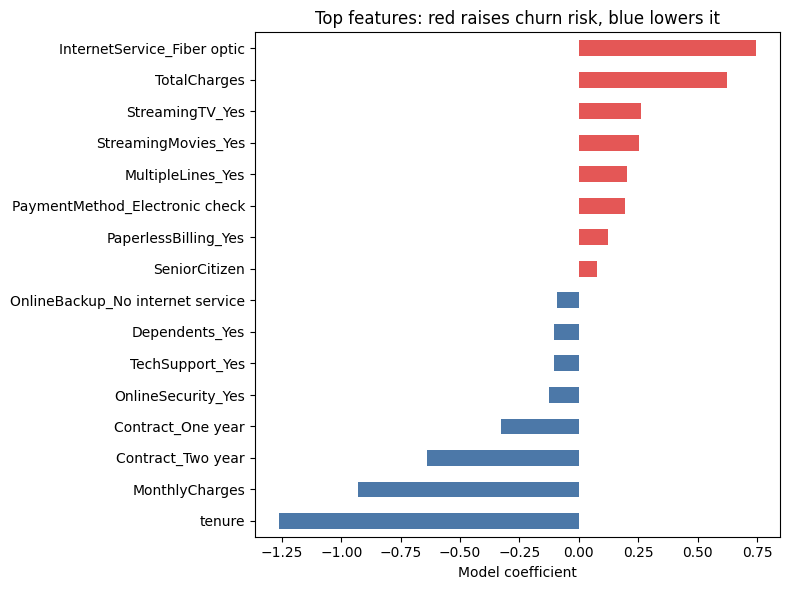

In [13]:
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])

plt.figure(figsize=(8, 6))
top.plot(kind='barh', color=['#4C78A8' if v < 0 else '#E45756' for v in top])
plt.title('Top features: red raises churn risk, blue lowers it')
plt.xlabel('Model coefficient')
plt.tight_layout()
plt.show()

The model separates churners from stayers reasonably well (ROC-AUC of about 0.84). Long tenure and one- or two-year contracts reduce churn risk, while fiber optic internet raises it. Note that `MonthlyCharges` and `TotalCharges` are strongly correlated with each other and with tenure, so their individual coefficients are hard to interpret; rely on the group comparisons in sections 4-8 for those.

## 10. Key insights

- Overall churn is about **26.6%**.
- **Contract type** is the biggest driver: month-to-month customers churn at ~43% vs ~11% (one year) and ~3% (two year).
- **New customers are the most at risk:** ~48% of customers in their first 12 months churn, versus under 10% after four years.
- **Fiber optic** customers churn at ~42%, more than double DSL (~19%).
- Customers **without tech support or online security** churn at ~42%, versus ~15% for those who have them.
- **Electronic check** payers churn at ~45%, versus ~15-19% for other payment methods.
- Churned customers pay higher monthly bills and leave early.

## 11. Business recommendations

1. **Move customers to longer contracts** with discounts or perks for 1- and 2-year plans.
2. **Strengthen onboarding in the first 12 months** with check-in calls, welcome offers and early support.
3. **Bundle tech support and online security** for free or at a discount, especially for fiber customers.
4. **Investigate fiber optic service quality and pricing**, since churn there is unusually high.
5. **Encourage automatic payments** (bank transfer or card) with a small incentive.
6. **Use the model** to flag high-risk customers for proactive retention offers.

*Note: this analysis shows associations, not proven causes. Test retention offers (for example with an A/B test) before rolling them out widely.*